# Layout

A calculator built from stacks and a grid: the keys size themselves to their labels, the keypad to the
keys and the card to the keypad, so changing one parameter re-lays out the whole design.

    python 17_layout.py                 writes 17_calculator.svg, 17_calculator_roomy.svg and 17_calculator.pdf

In [1]:
import svgwriter as svg

A key is a `VStack` holding one label, centred, with padding and a rounded background. The background
is sized to the stack, whatever the label.

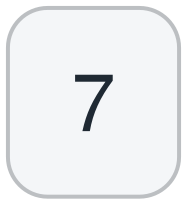

In [2]:
OPERATORS = "÷×−+="


def key(label: str) -> svg.VStack:
    """One calculator key: the label on a rounded rect, in the accent role for operators."""
    role = "accent" if label in OPERATORS else "box"
    return svg.VStack(svg.text(label, font_size=20).as_role("text"), padding=(12, 16), align="center",
                      background=svg.rect(rx=10).as_role(role))


seven = key("7")
seven

The keypad is a `Grid` of four equal columns. `"1fr"` columns without a fixed width take the widest key,
so every key comes out the same size, and the default `"stretch"` sizes each key to its cell. The zero
key spans two columns.

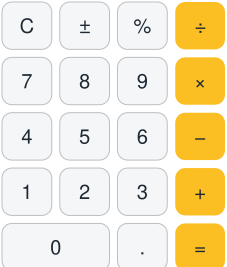

In [3]:
labels = ["C", "±", "%", "÷", "7", "8", "9", "×", "4", "5", "6", "−", "1", "2", "3", "+", "0", ".", "="]
keys = [key(label) for label in labels]
keypad = svg.Grid(*keys, columns=4, gap=8)
keypad.span(keys[labels.index("0")], columns=2)
keypad

The card stacks a display above the keypad. In the display a `Spacer` pushes the number to the right
edge, and `align="stretch"` makes the display as wide as the keypad.

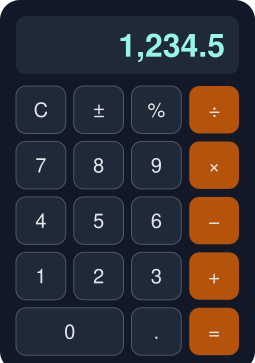

In [4]:
display = svg.HStack(svg.Spacer(), svg.text("1,234.5", font_size=32).as_role("title"),
                     padding=(10, 14), background=svg.rect(rx=10).as_role("surface"))
card = svg.VStack(display, keypad, gap=12, padding=16, align="stretch",
                  background=svg.rect(rx=20).as_role("background"))
doc = svg.Document(theme="dark")
doc += card
doc.save("17_calculator.svg")
doc

One parameter re-lays out everything: a wider gap moves the keys, grows the keypad and the display, and
enlarges the card and its background. Nothing is recomputed until the drawing is measured or written.

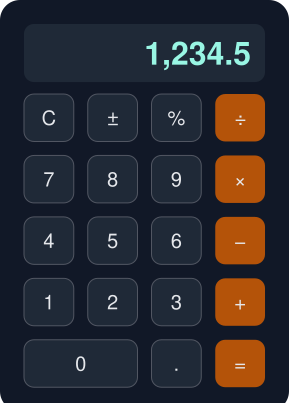

In [5]:
keypad.gap = 14
card.padding = 24
doc.save("17_calculator_roomy.svg")
doc

Changing content works the same way: a longer number widens the display, the card follows, and the
`"1fr"` columns share the new width. The output is plain groups with transforms, so the PDF (and every
other format) draws the same positions.

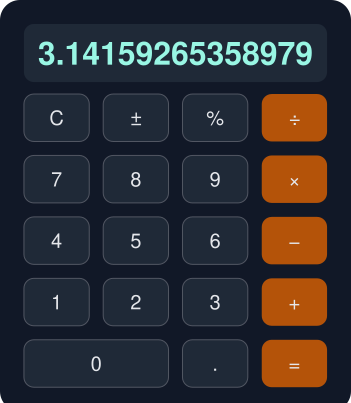

In [6]:
display[2].text_content = "3.14159265358979"
doc.save("17_calculator.pdf")
doc